In [ ]:
from google.colab import files
uploaded = files.upload()

Saving bgg_dataset.csv to bgg_dataset.csv


# **---------- Phase 1: Data Cleaning ----------**

In [ ]:
# 1.0) Load Dataset & Import Libraries
import pandas as pd
import numpy as np

df = pd.read_csv('bgg_dataset.csv', sep=';')
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

Loaded: 20,343 rows × 14 columns



In [ ]:
# 1.1) Duplication Removal
full_dups = df.duplicated().sum()
print(f"[1a] Full duplicate rows: {full_dups}")

before = len(df)
df = df.drop_duplicates(subset='ID', keep='first')
print(f"[1b] Removed {before - len(df)} duplicate-ID rows "
      f"({len(df):,} rows remaining)")

print(f"[1c] Duplicate Names kept intentionally "
      f"(different games can share a title)\n")

print("[2] No irrelevant columns found — all 14 columns retained.\n")

[1a] Full duplicate rows: 0
[1b] Removed 15 duplicate-ID rows (20,328 rows remaining)
[1c] Duplicate Names kept intentionally (different games can share a title)

[2] No irrelevant columns found — all 14 columns retained.



In [ ]:
# 1.2) Standardize Columns
for col in ['Rating Average', 'Complexity Average']:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors='coerce')
print("[3a] Fixed decimal format in 'Rating Average' and 'Complexity Average'.")

# 1.2.1) Convert numeric columns
df['ID']             = pd.to_numeric(df['ID'],             errors='coerce')
df['Year Published'] = pd.to_numeric(df['Year Published'], errors='coerce')
df['Owned Users']    = pd.to_numeric(df['Owned Users'],    errors='coerce')
print("[3b] Converted ID / Year Published / Owned Users to numeric.")

# 1.2.2) Trim whitespace from text columns
for col in ['Name', 'Mechanics', 'Domains']:
    df[col] = df[col].astype(str).str.strip()
print("[3c] Trimmed whitespace from Name, Mechanics, Domains.\n")

[3a] Fixed decimal format in 'Rating Average' and 'Complexity Average'.
[3b] Converted ID / Year Published / Owned Users to numeric.
[3c] Trimmed whitespace from Name, Mechanics, Domains.



In [ ]:
# 1.3) Handling Missing Values
df = df.dropna(subset=['Year Published'])
print("[4b] Dropped 1 row with missing Year Published.")


median_owned = df['Owned Users'].median()
df['Owned Users'] = df['Owned Users'].fillna(median_owned)
print(f"[4c] Filled 23 missing 'Owned Users' with median ({median_owned:.0f}).")


df['Mechanics'] = df['Mechanics'].replace('nan', np.nan).fillna('Unknown')
print("[4d] Filled 1,598 missing 'Mechanics' with 'Unknown'.")


df['Domains'] = df['Domains'].replace('nan', np.nan).fillna('Unknown')
print("[4e] Filled 10,159 missing 'Domains' with 'Unknown'.\n")

[4b] Dropped 1 row with missing Year Published.
[4c] Filled 23 missing 'Owned Users' with median (309).
[4d] Filled 1,598 missing 'Mechanics' with 'Unknown'.
[4e] Filled 10,159 missing 'Domains' with 'Unknown'.



In [ ]:
# 1.4) Fix Invalid and Implausible Values
df.loc[df['Year Published'] < 0, 'Year Published'] = np.nan
median_year = df['Year Published'].median()
df['Year Published'] = df['Year Published'].fillna(median_year).astype(int)
print(f"[5a] Replaced negative Year Published with median ({int(median_year)}).")


df.loc[df['Min Players'] == 0, 'Min Players'] = 1
print("[5b] Replaced 46 'Min Players == 0' with 1.")


df.loc[df['Max Players'] == 0, 'Max Players'] = np.nan
df['Max Players'] = df['Max Players'].fillna(df['Min Players']).astype(int)
print("[5c] Replaced 161 'Max Players == 0' with corresponding Min Players.")


df.loc[df['Play Time'] == 0, 'Play Time'] = np.nan
median_pt = df['Play Time'].median()
df['Play Time'] = df['Play Time'].fillna(median_pt).astype(int)
print(f"[5d] Fixed 556 zero 'Play Time' values (median={int(median_pt)} min).")


df.loc[df['Min Age'] == 0, 'Min Age'] = np.nan
median_age = df['Min Age'].median()
df['Min Age'] = df['Min Age'].fillna(median_age).astype(int)
print(f"[5e] Fixed 1,251 zero 'Min Age' values (median={int(median_age)}).")


df.loc[df['Complexity Average'] == 0, 'Complexity Average'] = np.nan
median_cx = df['Complexity Average'].median()
df['Complexity Average'] = df['Complexity Average'].fillna(median_cx)
df['Complexity Average'] = df['Complexity Average'].round(2)
print(f"[5f] Fixed 426 'Complexity Average == 0' (median={median_cx:.2f}); "
      f"kept within [1.0, 5.0].\n")


print("[5g] 'Users Rated', 'Owned Users', 'Rating Average' — "
      "original values preserved (no capping).\n")

[5a] Replaced negative Year Published with median (2011).
[5b] Replaced 46 'Min Players == 0' with 1.
[5c] Replaced 161 'Max Players == 0' with corresponding Min Players.
[5d] Fixed 556 zero 'Play Time' values (median=45 min).
[5e] Fixed 1,251 zero 'Min Age' values (median=10).
[5f] Fixed 426 'Complexity Average == 0' (median=2.00); kept within [1.0, 5.0].

[5g] 'Users Rated', 'Owned Users', 'Rating Average' — original values preserved (no capping).



In [ ]:
# 1.5) Finalize Data Types
df = df.dropna(subset=['ID'])

df['ID']             = df['ID'].astype(int)
df['Year Published'] = df['Year Published'].astype(int)
df['Min Players']    = df['Min Players'].astype(int)
df['Max Players']    = df['Max Players'].astype(int)
df['Play Time']      = df['Play Time'].astype(int)
df['Min Age']        = df['Min Age'].astype(int)
df['Users Rated']    = df['Users Rated'].astype(int)
df['BGG Rank']       = df['BGG Rank'].astype(int)
df['Owned Users']    = df['Owned Users'].astype(int)


print("[6] Final data types:")
print(df.dtypes, "\n")

[6] Final data types:
ID                      int64
Name                   object
Year Published          int64
Min Players             int64
Max Players             int64
Play Time               int64
Min Age                 int64
Users Rated             int64
Rating Average        float64
BGG Rank                int64
Complexity Average    float64
Owned Users             int64
Mechanics              object
Domains                object
dtype: object 



In [ ]:
# 1.6) Validation Report
print("=" * 55)
print("VALIDATION REPORT")
print("=" * 55)

errors = []

print(f"Final shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


missing = df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values remaining")
else:
    print("✗ Missing values found:")
    print(missing[missing > 0])
    errors.append("missing values")

dup_ids = df['ID'].duplicated().sum()
if dup_ids == 0:
    print("✓ No duplicate IDs")
else:
    print(f"✗ {dup_ids} duplicate IDs remain")
    errors.append("duplicate IDs")


bad_players = (df['Min Players'] > df['Max Players']).sum()
if bad_players == 0:
    print("✓ Min Players ≤ Max Players for all rows")
else:
    print(f"✗ {bad_players} rows still have Min > Max Players")
    errors.append("player logic")


for col in ['Min Players', 'Max Players', 'Play Time']:
    zeros = (df[col] == 0).sum()
    if zeros == 0:
        print(f"✓ No zero values in '{col}'")
    else:
        print(f"✗ {zeros} zero values in '{col}'")
        errors.append(f"zeros in {col}")


checks = {
    'Rating Average':     (1.0, 10.0),
    'Complexity Average': (1.0, 5.0),
    'Min Players':        (1,   None),
    'Year Published':     (0,   2025),
}
for col, (lo, hi) in checks.items():
    out_lo = (df[col] < lo).sum() if lo is not None else 0
    out_hi = (df[col] > hi).sum() if hi is not None else 0
    if out_lo + out_hi == 0:
        print(f"✓ '{col}' values within expected range")
    else:
        print(f"✗ '{col}' has {out_lo + out_hi} out-of-range values "
              f"[{lo}, {hi}]")
        errors.append(f"range: {col}")


expected_int = ['ID','Year Published','Min Players','Max Players',
                'Play Time','Min Age','Users Rated','BGG Rank','Owned Users']
for col in expected_int:
    if df[col].dtype != 'int64':
        print(f"✗ '{col}' expected int64, got {df[col].dtype}")
        errors.append(f"dtype: {col}")
    else:
        print(f"✓ '{col}' is int64")

for col in ['Rating Average', 'Complexity Average']:
    if df[col].dtype != 'float64':
        print(f"✗ '{col}' expected float64, got {df[col].dtype}")
        errors.append(f"dtype: {col}")
    else:
        print(f"✓ '{col}' is float64")


for col in ['Users Rated', 'Owned Users', 'Rating Average']:
    nunique = df[col].nunique()
    print(f"✓ '{col}' has {nunique:,} unique values (not constant)")

print()
if not errors:
    print("ALL CHECKS PASSED ✓ — dataset is clean.")
else:
    print(f"ISSUES REMAINING: {errors}")
print("=" * 55)

VALIDATION REPORT
Final shape: 20,327 rows × 14 columns
✓ No missing values remaining
✓ No duplicate IDs
✓ Min Players ≤ Max Players for all rows
✓ No zero values in 'Min Players'
✓ No zero values in 'Max Players'
✓ No zero values in 'Play Time'
✓ 'Rating Average' values within expected range
✓ 'Complexity Average' values within expected range
✓ 'Min Players' values within expected range
✓ 'Year Published' values within expected range
✓ 'ID' is int64
✓ 'Year Published' is int64
✓ 'Min Players' is int64
✓ 'Max Players' is int64
✓ 'Play Time' is int64
✓ 'Min Age' is int64
✓ 'Users Rated' is int64
✓ 'BGG Rank' is int64
✓ 'Owned Users' is int64
✓ 'Rating Average' is float64
✓ 'Complexity Average' is float64
✓ 'Users Rated' has 2,973 unique values (not constant)
✓ 'Owned Users' has 3,997 unique values (not constant)
✓ 'Rating Average' has 621 unique values (not constant)

ALL CHECKS PASSED ✓ — dataset is clean.


In [ ]:
# 1.7) Export Cleaned Dataset
df = df.reset_index(drop=True)
df.to_csv('bgg_dataset_cleaned.csv', index=False)
print("\nCleaned dataset saved as 'bgg_dataset_cleaned.csv'")


Cleaned dataset saved as 'bgg_dataset_cleaned.csv'


# **---------- Phase 2: Preprocessing ----------**

In [ ]:
# 2.0) Import Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from collections import Counter

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# 2.1) Drop Non-Feature Columns
df = df.drop(columns=['ID', 'Name'])
print("Dropped ID and Name columns.")
print("New shape:", df.shape)

Dropped ID and Name columns.
New shape: (20327, 12)


In [ ]:
# 2.2) Outlier Removal (IQR Filtering on Numeric Columns)
numeric_cols = ['Play Time', 'Min Age',
                'Users Rated', 'Complexity Average', 'Owned Users']

def remove_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    return df[(df[col] >= Q1 - 1.5 * IQR) & (df[col] <= Q3 + 1.5 * IQR)]

for col in numeric_cols:
    before = len(df)
    df = remove_outliers_iqr(df, col)
    print(f"{col}: removed {before - len(df)} outlier rows")

print(f"\nShape after outlier removal: {df.shape}")

Play Time: removed 1373 outlier rows
Min Age: removed 14 outlier rows
Users Rated: removed 2714 outlier rows
Complexity Average: removed 141 outlier rows
Owned Users: removed 1245 outlier rows

Shape after outlier removal: (14840, 12)


In [ ]:
# 2.3) Multi-Hot Encode 'Mechanics' Column
df['Mechanics'] = df['Mechanics'].fillna('')

mechanic_counts = Counter()
df['Mechanics'].str.split(', ').apply(mechanic_counts.update)
top_mechanics = [m for m, _ in mechanic_counts.most_common(20) if m and m != 'Unknown']

for mechanic in top_mechanics:
    col_name = 'mech_' + mechanic.replace(' ', '_').replace('/', '_')
    df[col_name] = df['Mechanics'].str.contains(mechanic, regex=False).astype(int)

df = df.drop(columns=['Mechanics'])
print(f"Top 20 mechanics encoded as binary columns.")
print(f"New shape: {df.shape}")

Top 20 mechanics encoded as binary columns.
New shape: (14840, 30)


In [ ]:
# 2.4) Multi-Hot Encode 'Domains' Column
df['Domains'] = df['Domains'].fillna('')

domain_counts = Counter()
df['Domains'].str.split(', ').apply(domain_counts.update)
all_domains = [d for d, _ in domain_counts.most_common() if d and d != 'Unknown']

for domain in all_domains:
    col_name = 'domain_' + domain.replace(' ', '_')
    df[col_name] = df['Domains'].str.contains(domain, regex=False).astype(int)

df = df.drop(columns=['Domains'])
print(f"Domains encoded as binary columns.")
print(f"New shape: {df.shape}")

Domains encoded as binary columns.
New shape: (14840, 37)


# **---------- Phase 3: Feature Engineering ----------**

In [ ]:
# 3.1) Player Range
df['Player Range'] = df['Max Players'] - df['Min Players']

In [ ]:
# 3.2) Average Recommended Players
df['Average Players'] = (df['Min Players'] + df['Max Players']) / 2

In [ ]:
# 3.3) Game Age
CURRENT_YEAR = 2026
df['Game Age'] = CURRENT_YEAR - df['Year Published']

In [ ]:
# 3.4) Play Time Category
df['Play Time Category'] = pd.cut(
    df['Play Time'],
    bins=[0, 30, 90, 180, np.inf],
    labels=['Short', 'Medium', 'Long', 'Very Long']
).map({'Short': 0, 'Medium': 1, 'Long': 2, 'Very Long': 3}).astype(int)

In [ ]:
# 3.5) Complexity Category
df['Complexity Category'] = pd.cut(
    df['Complexity Average'],
    bins=[0, 2, 3, 4, 5],
    labels=['Easy', 'Moderate', 'Hard', 'Expert']
).map({'Easy': 0, 'Moderate': 1, 'Hard': 2, 'Expert': 3}).astype(int)

In [ ]:
# 3.6) Popularity-Complexity Interaction
df['Pop_Complexity'] = df['Users Rated'] * df['Complexity Average']

In [ ]:
# 3.7) Rating Category (Target Variable)
bins = [0.0, 6.0, 7.5, 10.0]
labels = ['Low', 'Medium', 'High']

df['Rating Category'] = pd.cut(
    df['Rating Average'],
    bins=bins,
    labels=labels,
    include_lowest=True
).map({'Low': 0, 'Medium': 1, 'High': 2}).astype(int)

In [ ]:
# 3.8) Inspect New Features
print(df[['Rating Average', 'Rating Category',
          'Player Range', 'Average Players',
          'Game Age', 'Play Time Category',
          'Complexity Category']].head())
print("\nRating Category Distribution:")
print(df['Rating Category'].value_counts().sort_index())
print(f"\nNew shape: {df.shape}")

      Rating Average  Rating Category  Player Range  Average Players  \
1594            7.90                2             2              3.0   
1832            7.88                2             3              2.5   
1870            7.67                2             3              2.5   
1897            7.58                2             3              3.5   
1995            7.30                1             3              3.5   

      Game Age  Play Time Category  Complexity Category  
1594         6                   2                    2  
1832         5                   2                    2  
1870        12                   2                    2  
1897        10                   2                    1  
1995        19                   1                    1  

Rating Category Distribution:
Rating Category
0    5877
1    7839
2    1124
Name: count, dtype: int64

New shape: (14840, 44)


# **---------- Phase 4: Model Preparation ----------**

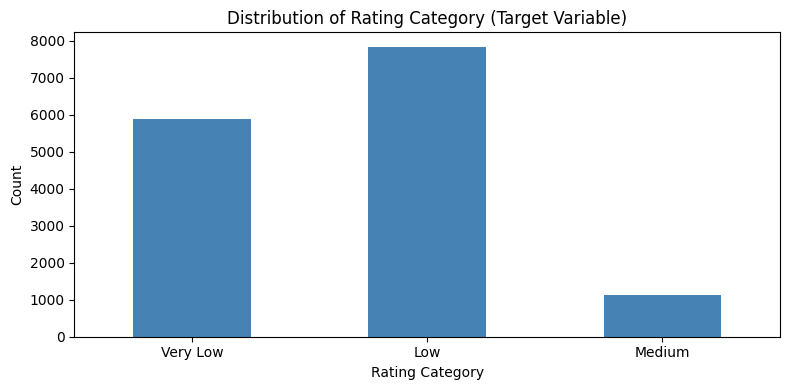

In [ ]:
# 4.1) Visualize Target Variable Distribution (Rating Category)
label_map = {0: 'Very Low', 1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'}

plt.figure(figsize=(8, 4))
df['Rating Category'].value_counts().sort_index().rename(index=label_map).plot(
    kind='bar', color='steelblue'
)
plt.title('Distribution of Rating Category (Target Variable)')
plt.xlabel('Rating Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

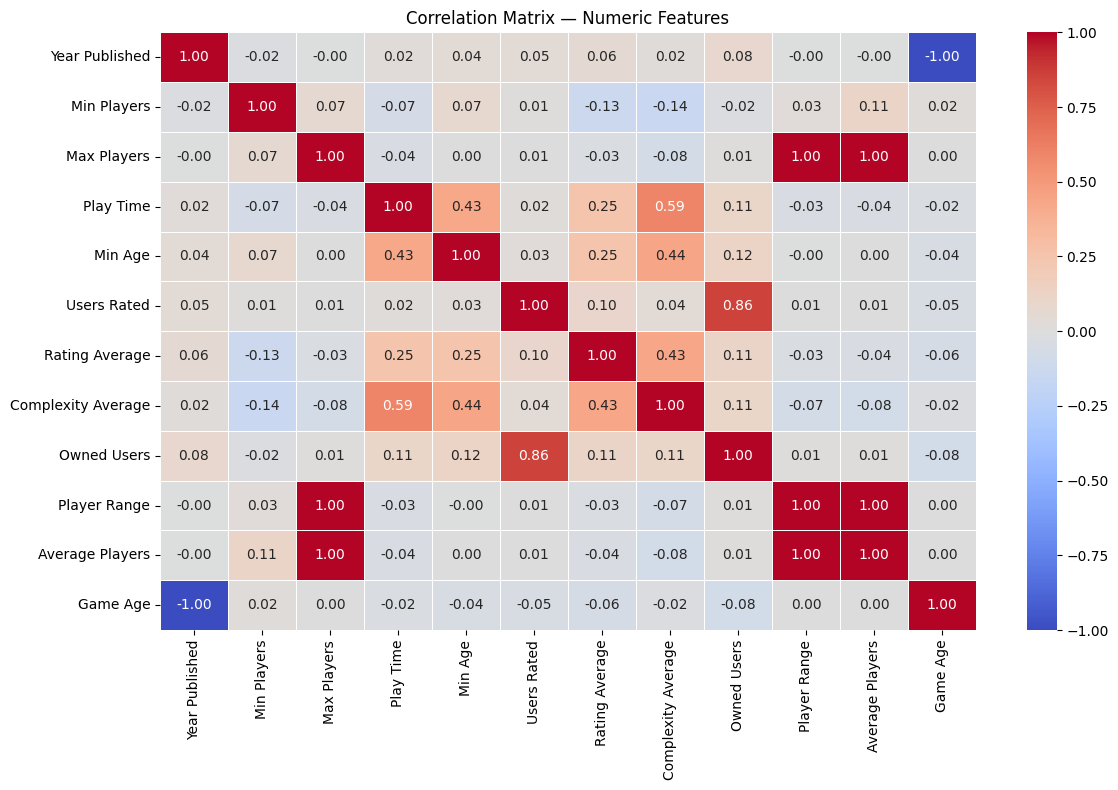

In [ ]:
# 4.2) Correlation Matrix of Numeric Features
base_numeric = ['Year Published', 'Min Players', 'Max Players', 'Play Time',
                'Min Age', 'Users Rated', 'Rating Average',
                'Complexity Average', 'Owned Users',
                'Player Range', 'Average Players', 'Game Age']

plt.figure(figsize=(12, 8))
sns.heatmap(df[base_numeric].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix — Numeric Features')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 4.3) Train-Test Split (80/20)
X = df.drop(columns=['Rating Average', 'Rating Category', 'BGG Rank'])
y = df['Rating Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set:  {X_train.shape[0]:,} rows, {X_train.shape[1]} features")
print(f"Testing set:   {X_test.shape[0]:,} rows, {X_test.shape[1]} features")
print(f"\nTarget variable (y) — Rating Category:")
print(y_train.value_counts().sort_index())

Training set:  11,872 rows, 41 features
Testing set:   2,968 rows, 41 features

Target variable (y) — Rating Category:
Rating Category
0    4702
1    6271
2     899
Name: count, dtype: int64


In [ ]:
# 4.4) Scale Numeric Features (Min-Max Normalization)
scale_cols = ['Year Published', 'Min Players', 'Max Players', 'Play Time',
              'Min Age', 'Users Rated', 'Complexity Average', 'Owned Users',
              'Player Range', 'Average Players', 'Game Age', 'Pop_Complexity']

scaler = MinMaxScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

print("Numeric features scaled to 0-1 range.")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

Numeric features scaled to 0-1 range.
X_train: (11872, 41) | X_test: (2968, 41)


In [ ]:
# 4.5) Export Preprocessed Data
from google.colab import files

X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print("Exported: X_train, X_test, y_train, y_test")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

Exported: X_train, X_test, y_train, y_test
X_train: (11872, 41) | X_test: (2968, 41)


# **---------- Phase 5: Modelling ----------**

In [ ]:
# 5.0) Modelling Setup
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

!pip install xgboost -q
from xgboost import XGBClassifier

label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
results   = {}
tuned     = {}

def evaluate(name, model, X_tr, y_tr, X_te, y_te, store_in=None):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    f1  = f1_score(y_te, y_pred, average='weighted')

    if store_in is not None:
      store_in[name] = {
        'Model': model,
        'Accuracy': acc,
        'Weighted F1': f1
    }

    print(f"  Accuracy:    {acc:.4f}")
    print(f"  Weighted F1: {f1:.4f}")
    print(f"\n{classification_report(y_te, y_pred, target_names=label_map.values())}")
    plt.figure(figsize=(7, 5))
    sns.heatmap(confusion_matrix(y_te, y_pred),
                annot=True, fmt='d', cmap='Blues',
                xticklabels=label_map.values(),
                yticklabels=label_map.values())
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()
    return model

def tune(name, model, param_grid, X_tr, y_tr, X_te, y_te):
    search = GridSearchCV(model, param_grid,
                          cv=5, scoring='accuracy', n_jobs=-1)
    search.fit(X_tr, y_tr)
    print(f"  Best Params:")
    for k, v in search.best_params_.items():
        print(f"    {k}: {v}")
    print(f"  CV Best Score: {search.best_score_:.4f}")
    return evaluate(name, search.best_estimator_,
                    X_tr, y_tr, X_te, y_te, store_in=tuned)

print("Setup complete.")

Setup complete.


# **---------- Phase 5.A: Logistic Regression ----------**

[ Base Model ]
  Accuracy:    0.5391
  Weighted F1: 0.5521

              precision    recall  f1-score   support

         Low       0.62      0.70      0.66      1175
      Medium       0.71      0.40      0.51      1568
        High       0.20      0.67      0.31       225

    accuracy                           0.54      2968
   macro avg       0.51      0.59      0.49      2968
weighted avg       0.63      0.54      0.55      2968



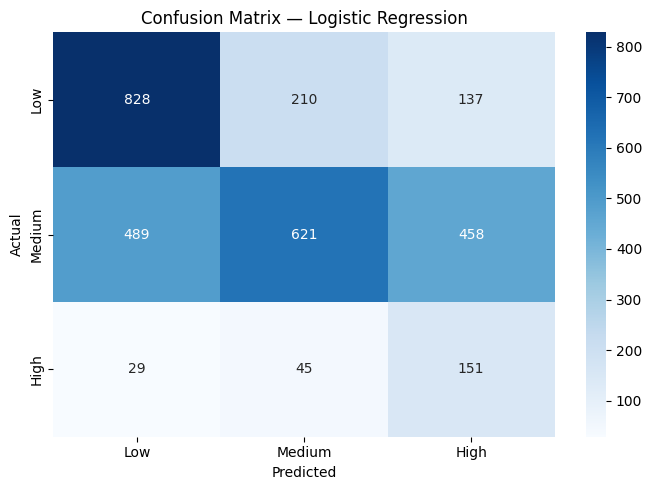

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
# 5.A.1) Base Model
print("[ Base Model ]")
evaluate('Logistic Regression',
         LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    C: 100
  CV Best Score: 0.6358
  Accuracy:    0.6557
  Weighted F1: 0.6353

              precision    recall  f1-score   support

         Low       0.67      0.59      0.63      1175
      Medium       0.65      0.78      0.71      1568
        High       0.49      0.08      0.13       225

    accuracy                           0.66      2968
   macro avg       0.60      0.48      0.49      2968
weighted avg       0.65      0.66      0.64      2968



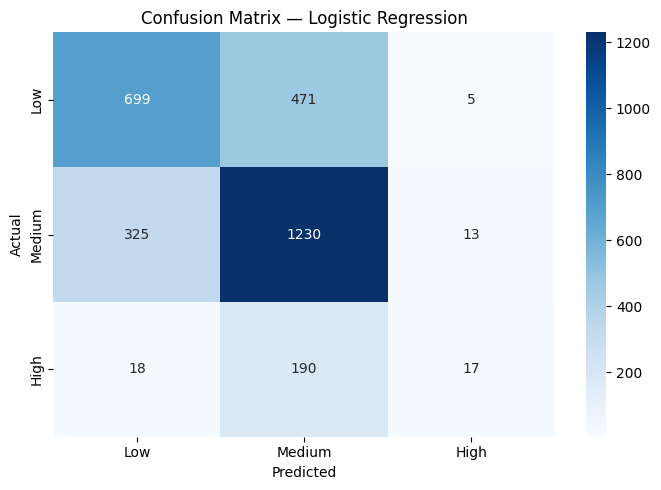

LogisticRegression(C=100, max_iter=1000, random_state=42)

In [ ]:
# 5.A.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('Logistic Regression',
     LogisticRegression(max_iter=1000, random_state=42),
     {'C': [0.01, 0.1, 1, 10, 100]},
     X_train, y_train, X_test, y_test)

# **---------- Phase 5.B: K-Nearest Neighbors ----------**

[ Base Model ]
  Accuracy:    0.5930
  Weighted F1: 0.5808

              precision    recall  f1-score   support

         Low       0.56      0.59      0.58      1175
      Medium       0.62      0.67      0.64      1568
        High       0.36      0.11      0.16       225

    accuracy                           0.59      2968
   macro avg       0.52      0.45      0.46      2968
weighted avg       0.58      0.59      0.58      2968



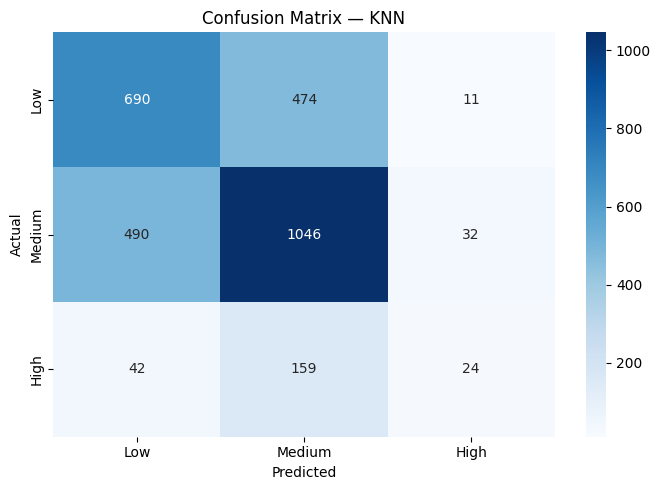

KNeighborsClassifier()

In [ ]:
# 5.B.1) Base Model
print("[ Base Model ]")
evaluate('KNN',
         KNeighborsClassifier(n_neighbors=5),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    metric: manhattan
    n_neighbors: 11
    weights: distance
  CV Best Score: 0.6108
  Accuracy:    0.6196
  Weighted F1: 0.6067

              precision    recall  f1-score   support

         Low       0.62      0.58      0.59      1175
      Medium       0.63      0.72      0.67      1568
        High       0.39      0.13      0.20       225

    accuracy                           0.62      2968
   macro avg       0.55      0.48      0.49      2968
weighted avg       0.61      0.62      0.61      2968



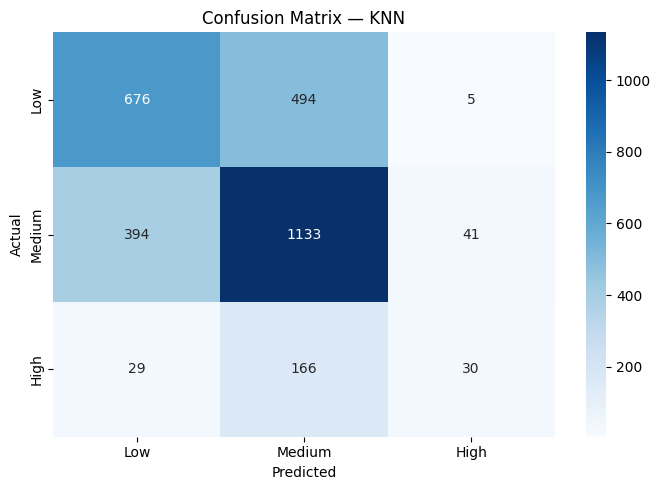

KNeighborsClassifier(metric='manhattan', n_neighbors=11, weights='distance')

In [ ]:
# 5.B.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('KNN',
     KNeighborsClassifier(),
     {'n_neighbors': [3, 5, 7, 9, 11],
      'weights':     ['uniform', 'distance'],
      'metric':      ['euclidean', 'manhattan']},
     X_train, y_train, X_test, y_test)

# **---------- Phase 5.C: Decision Tree ----------**

[ Base Model ]
  Accuracy:    0.5954
  Weighted F1: 0.5952

              precision    recall  f1-score   support

         Low       0.60      0.58      0.59      1175
      Medium       0.63      0.64      0.64      1568
        High       0.34      0.35      0.34       225

    accuracy                           0.60      2968
   macro avg       0.52      0.52      0.52      2968
weighted avg       0.60      0.60      0.60      2968



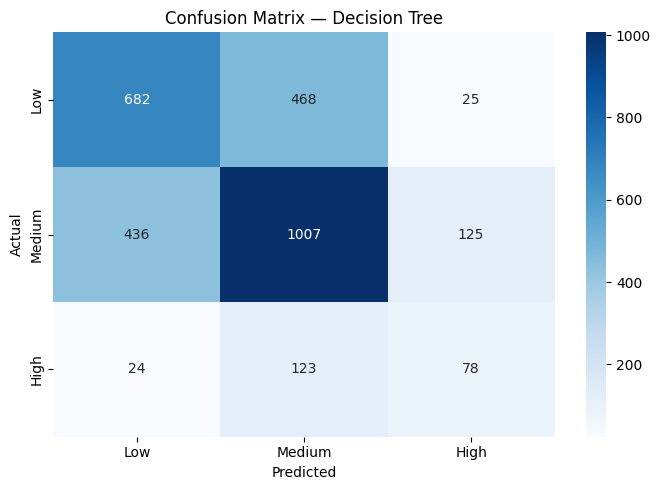

DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [ ]:
# 5.C.1) Base Model
print("[ Base Model ]")
evaluate('Decision Tree',
         DecisionTreeClassifier(random_state=42, class_weight='balanced'),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    criterion: gini
    max_depth: 15
    min_samples_leaf: 1
  CV Best Score: 0.6147
  Accuracy:    0.6173
  Weighted F1: 0.6194

              precision    recall  f1-score   support

         Low       0.62      0.68      0.65      1175
      Medium       0.67      0.61      0.64      1568
        High       0.31      0.37      0.34       225

    accuracy                           0.62      2968
   macro avg       0.53      0.55      0.54      2968
weighted avg       0.62      0.62      0.62      2968



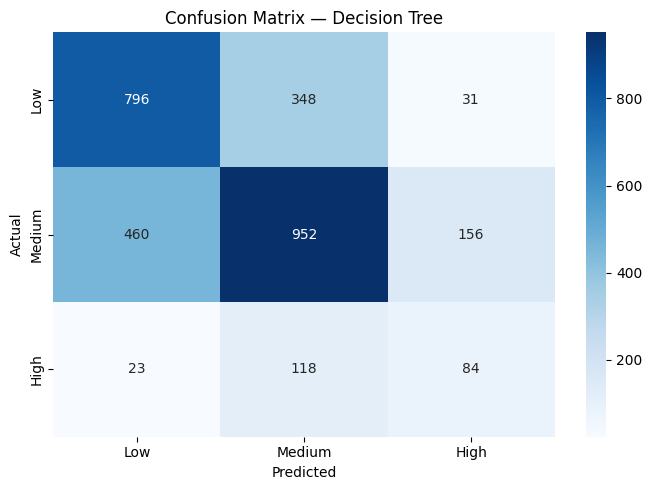

DecisionTreeClassifier(class_weight='balanced', max_depth=15, random_state=42)

In [ ]:
# 5.C.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('Decision Tree',
     DecisionTreeClassifier(random_state=42, class_weight='balanced'),
     {'max_depth': [3, 5, 10, 15, None],
      'criterion': ['gini', 'entropy'],
      'min_samples_leaf': [1, 2, 4]},
     X_train, y_train, X_test, y_test)

# **---------- Phase 5.D: Random Forest ----------**

[ Base Model ]
  Accuracy:    0.7086
  Weighted F1: 0.7005

              precision    recall  f1-score   support

         Low       0.73      0.68      0.70      1175
      Medium       0.70      0.79      0.74      1568
        High       0.60      0.28      0.38       225

    accuracy                           0.71      2968
   macro avg       0.68      0.58      0.61      2968
weighted avg       0.71      0.71      0.70      2968



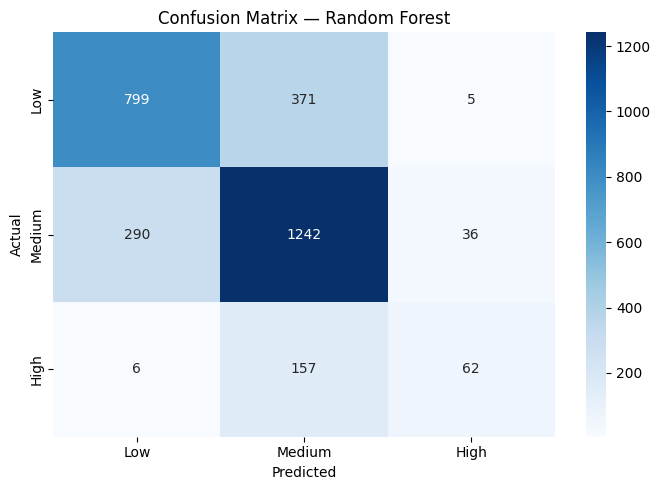

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# 5.D.1) Base Model
print("[ Base Model ]")
evaluate('Random Forest',
         RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    max_depth: None
    max_features: sqrt
    min_samples_leaf: 2
    n_estimators: 200
  CV Best Score: 0.7048
  Accuracy:    0.7086
  Weighted F1: 0.7015

              precision    recall  f1-score   support

         Low       0.73      0.68      0.70      1175
      Medium       0.70      0.79      0.74      1568
        High       0.62      0.30      0.41       225

    accuracy                           0.71      2968
   macro avg       0.68      0.59      0.62      2968
weighted avg       0.71      0.71      0.70      2968



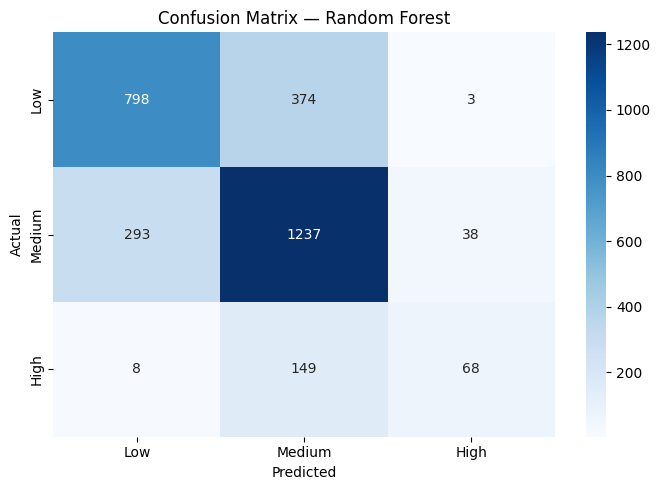

RandomForestClassifier(min_samples_leaf=2, n_estimators=200, random_state=42)

In [ ]:
# 5.D.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('Random Forest',
     RandomForestClassifier(random_state=42),
     {'n_estimators':      [100, 200],
      'max_depth':         [10, None],
      'max_features':      ['sqrt', 'log2'],
      'min_samples_leaf':  [1, 2]},
     X_train, y_train, X_test, y_test)

# **---------- Phase 5.E: Gradient Boosting ----------**

[ Base Model ]
  Accuracy:    0.7224
  Weighted F1: 0.7159

              precision    recall  f1-score   support

         Low       0.74      0.69      0.72      1175
      Medium       0.71      0.80      0.75      1568
        High       0.68      0.33      0.45       225

    accuracy                           0.72      2968
   macro avg       0.71      0.61      0.64      2968
weighted avg       0.72      0.72      0.72      2968



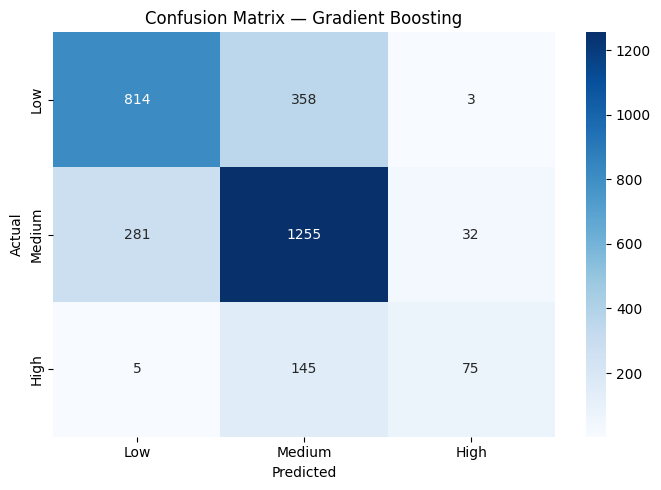

GradientBoostingClassifier(random_state=42)

In [ ]:
# 5.E.1) Base Model
print("[ Base Model ]")
evaluate('Gradient Boosting',
         GradientBoostingClassifier(n_estimators=100, random_state=42),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    learning_rate: 0.1
    max_depth: 3
    n_estimators: 200
    subsample: 0.8
  CV Best Score: 0.7079
  Accuracy:    0.7281
  Weighted F1: 0.7229

              precision    recall  f1-score   support

         Low       0.74      0.71      0.72      1175
      Medium       0.72      0.80      0.76      1568
        High       0.66      0.36      0.47       225

    accuracy                           0.73      2968
   macro avg       0.71      0.62      0.65      2968
weighted avg       0.73      0.73      0.72      2968



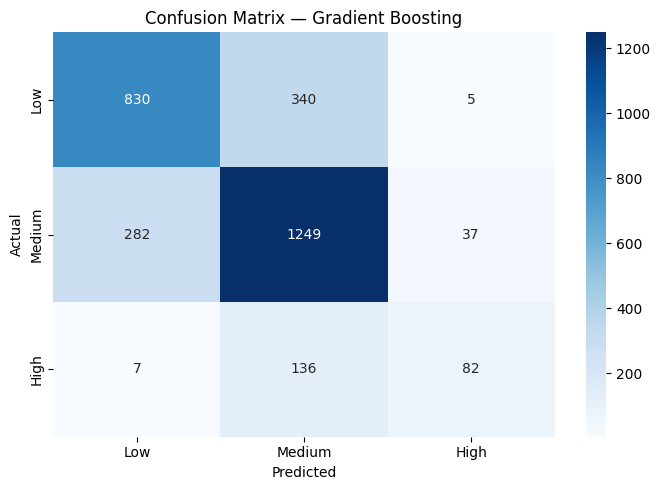

GradientBoostingClassifier(n_estimators=200, random_state=42, subsample=0.8)

In [ ]:
# 5.E.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('Gradient Boosting',
     GradientBoostingClassifier(random_state=42),
     {'n_estimators':  [100, 200],
      'learning_rate': [0.05, 0.1, 0.2],
      'max_depth':     [3, 5],
      'subsample':     [0.8, 1.0]},
     X_train, y_train, X_test, y_test)

# **---------- Phase 5.F: XGBoost ----------**

[ Base Model ]
  Accuracy:    0.7163
  Weighted F1: 0.7113

              precision    recall  f1-score   support

         Low       0.73      0.70      0.71      1175
      Medium       0.72      0.78      0.75      1568
        High       0.58      0.35      0.43       225

    accuracy                           0.72      2968
   macro avg       0.68      0.61      0.63      2968
weighted avg       0.71      0.72      0.71      2968



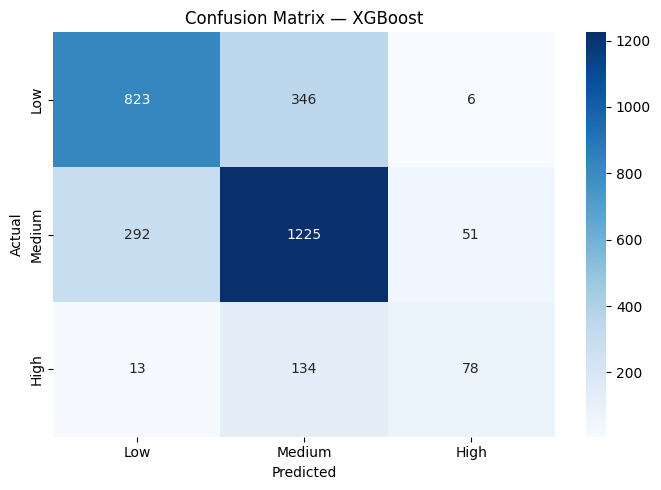

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=-1, num_class=3, ...)

In [ ]:
# 5.F.1) Base Model
print("[ Base Model ]")
evaluate('XGBoost',
         XGBClassifier(
             objective='multi:softmax',
             num_class=3,
             eval_metric='mlogloss',
             random_state=42,
             n_jobs=-1
         ),
         X_train, y_train, X_test, y_test,
         store_in=results)

[ Hyperparameter Tuning ]
  Best Params:
    colsample_bytree: 0.8
    learning_rate: 0.1
    max_depth: 5
    n_estimators: 200
  CV Best Score: 0.7093
  Accuracy:    0.7180
  Weighted F1: 0.7127

              precision    recall  f1-score   support

         Low       0.72      0.71      0.72      1175
      Medium       0.72      0.77      0.75      1568
        High       0.64      0.34      0.45       225

    accuracy                           0.72      2968
   macro avg       0.69      0.61      0.64      2968
weighted avg       0.72      0.72      0.71      2968



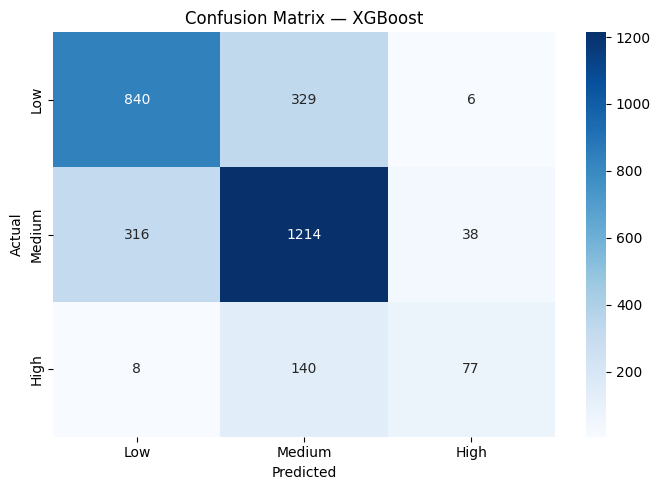

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1, num_class=3, ...)

In [ ]:
# 5.F.2) Hyperparameter Tuning
print("[ Hyperparameter Tuning ]")
tune('XGBoost',
     XGBClassifier(
         objective='multi:softmax',
         num_class=3,
         eval_metric='mlogloss',
         random_state=42,
         n_jobs=-1
     ),
     {'n_estimators':       [100, 200],
      'learning_rate':      [0.05, 0.1, 0.2],
      'max_depth':          [3, 5],
      'colsample_bytree':   [0.8, 1.0]},
     X_train, y_train, X_test, y_test)

# **---------- Phase 6: Model Evaluation ----------**

In [ ]:
# 6.1) Summary Table
before = pd.DataFrame(results).T.drop(columns=['Model'], errors='ignore').astype(float)
after  = pd.DataFrame(tuned).T.drop(columns=['Model'], errors='ignore').astype(float)
comparison = pd.concat([before, after], axis=1,
                       keys=['Before Tuning', 'After Tuning'])

print(comparison.round(4))

                    Before Tuning             After Tuning            
                         Accuracy Weighted F1     Accuracy Weighted F1
Logistic Regression        0.5391      0.5521       0.6557      0.6353
KNN                        0.5930      0.5808       0.6196      0.6067
Decision Tree              0.5954      0.5952       0.6173      0.6194
Random Forest              0.7086      0.7005       0.7086      0.7015
Gradient Boosting          0.7224      0.7159       0.7281      0.7229
XGBoost                    0.7163      0.7113       0.7180      0.7127


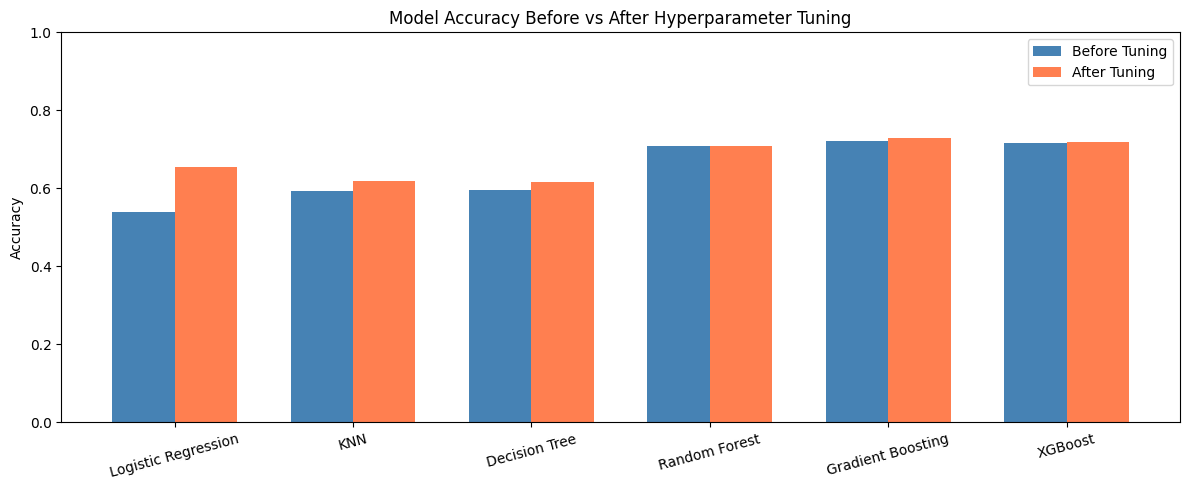

In [ ]:
# 6.2) Before vs After Accuracy Chart
fig, ax = plt.subplots(figsize=(12, 5))
x     = range(len(before))
width = 0.35
ax.bar([i - width/2 for i in x], before['Accuracy'],
       width, label='Before Tuning', color='steelblue')
ax.bar([i + width/2 for i in x], after['Accuracy'],
       width, label='After Tuning',  color='coral')
ax.set_xticks(list(x))
ax.set_xticklabels(before.index, rotation=15)
ax.set_ylabel('Accuracy')
ax.set_title('Model Accuracy Before vs After Hyperparameter Tuning')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 6.3) Best Model
best_model = after['Accuracy'].idxmax()
best_acc   = after['Accuracy'].max()
print(f"\nBest Model: {best_model} (Accuracy: {best_acc:.4f})")


Best Model: Gradient Boosting (Accuracy: 0.7281)


# **---------- Phase 7: Basic-Level Deployment ----------**

In [ ]:
# 7.0) Install & Setup
!pip install gradio -q
import gradio as gr
import matplotlib
import matplotlib.pyplot as plt
matplotlib.use('Agg')

final_model = tuned[best_model]['Model']
model_names = list(results.keys())

print(f"✓ Model loaded   : {best_model}")
print(f"✓ Test accuracy  : {tuned[best_model]['Accuracy']:.4f}")
print(f"✓ Weighted F1    : {tuned[best_model]['Weighted F1']:.4f}")
print(f"✓ Feature count  : {X_train.shape[1]}")
print(f"✓ Training rows  : {X_train.shape[0]:,}")

✓ Model loaded   : Gradient Boosting
✓ Test accuracy  : 0.7281
✓ Weighted F1    : 0.7229
✓ Feature count  : 41
✓ Training rows  : 11,872


In [ ]:
# 7.1) Prediction Function & Visualization Helper
def make_confidence_chart(confidence):
    palette = {
        'Low':    '#ef5350',
        'Medium': '#ffa726',
        'High':   '#66bb6a'
    }
    labels = list(confidence.keys())
    values = [confidence[k] * 100 for k in labels]
    colors = [palette[k] for k in labels]

    fig, ax = plt.subplots(figsize=(5.5, 2.2))
    fig.patch.set_facecolor('#fafafa')
    ax.set_facecolor('#fafafa')

    bars = ax.barh(labels, values, color=colors,
                   height=0.45, edgecolor='white', linewidth=1.5)

    for bar, val in zip(bars, values):
        ax.text(
            min(val + 1.5, 97),
            bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%',
            va='center', ha='left',
            fontsize=11, fontweight='bold', color='#333'
        )

    ax.set_xlim(0, 110)
    ax.set_xlabel('Confidence (%)', fontsize=9, color='#666')
    ax.set_title('Confidence per Class', fontsize=11,
                 fontweight='bold', color='#333', pad=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#ddd')
    ax.spines['bottom'].set_color('#ddd')
    ax.tick_params(colors='#555', labelsize=10)
    plt.tight_layout()
    return fig


def predict_game_rating(
    year, min_players, max_players, play_time, min_age,
    complexity, users_rated, owned_users,
    selected_mechanics, selected_domains
):
    if max_players < min_players:
        return (
            """<div style='background:#fff3e0;border-left:5px solid #ff9800;
               border-radius:8px;padding:1rem;font-family:Segoe UI,sans-serif;'>
               ⚠️ <b>Invalid Input:</b> Max Players must be ≥ Min Players.</div>""",
            None
        )

    sample = pd.DataFrame(
        np.zeros((1, len(X_train.columns))),
        columns=X_train.columns
    )

    # Core features
    sample['Year Published']     = year
    sample['Min Players']        = min_players
    sample['Max Players']        = max_players
    sample['Play Time']          = play_time
    sample['Min Age']            = min_age
    sample['Complexity Average'] = complexity
    sample['Users Rated']        = users_rated
    sample['Owned Users']        = owned_users

    # Engineered features
    sample['Player Range']    = max_players - min_players
    sample['Average Players'] = (min_players + max_players) / 2
    sample['Game Age']        = CURRENT_YEAR - year
    sample['Pop_Complexity']  = users_rated * complexity

    # Play Time Category
    if   play_time <= 30:  sample['Play Time Category'] = 0
    elif play_time <= 90:  sample['Play Time Category'] = 1
    elif play_time <= 180: sample['Play Time Category'] = 2
    else:                  sample['Play Time Category'] = 3

    # Complexity Category
    if   complexity < 2: sample['Complexity Category'] = 0
    elif complexity < 3: sample['Complexity Category'] = 1
    elif complexity < 4: sample['Complexity Category'] = 2
    else:                sample['Complexity Category'] = 3

    # Mechanics & Domains
    for mech in top_mechanics:
        col = 'mech_' + mech.replace(' ', '_').replace('/', '_')
        sample[col] = int(mech in (selected_mechanics or []))
    for d in all_domains:
        col = 'domain_' + d.replace(' ', '_')
        sample[col] = int(d in (selected_domains or []))

    # Scale & predict
    sample[scale_cols] = scaler.transform(sample[scale_cols])
    pred_class         = final_model.predict(sample)[0]
    pred_label         = label_map[pred_class]

    if hasattr(final_model, 'predict_proba'):
        probs      = final_model.predict_proba(sample)[0]
        confidence = {label_map[i]: float(probs[i])
                      for i in range(len(label_map))}
    else:
        confidence = {k: (1.0 if k == pred_label else 0.0)
                      for k in label_map.values()}

    top_conf = confidence[pred_label] * 100

    card_cfg = {
        'Low':    ('🔴', '#b71c1c', '#ffebee', '#ef9a9a',
                   'This game is predicted to receive <span style="font-weight:800;color:#b71c1c;">below-average</span> '
                   'community ratings based on its design profile.'),
        'Medium': ('🟡', '#e65100', '#fff8e1', '#ffcc80',
                   'This game is predicted to receive <span style="font-weight:800;color:#e65100;">average to solid</span> '
                   'community ratings based on its design profile.'),
        'High':   ('🟢', '#1b5e20', '#e8f5e9', '#a5d6a7',
                   'This game is predicted to receive <span style="font-weight:800;color:#1b5e20;">top-tier</span> '
                   'community ratings based on its design profile.'),
    }
    emoji, text_col, bg_col, border_col, desc = card_cfg[pred_label]

    result_html = f"""
    <div style="
        background: {bg_col};
        border: 2px solid {border_col};
        border-radius: 14px;
        padding: 1.8rem 2rem;
        text-align: center;
        font-family: 'Segoe UI', sans-serif;
        box-shadow: 0 3px 12px rgba(0,0,0,0.08);
    ">
        <div style="font-size:3.2rem;margin-bottom:0.4rem;">{emoji}</div>
        <div style="
            font-size: 0.8rem;
            color: #888;
            text-transform: uppercase;
            letter-spacing: 1px;
            margin-bottom: 0.2rem;
        ">Predicted Rating</div>
        <div style="
            font-size: 2.2rem;
            font-weight: 800;
            color: {text_col};
            margin-bottom: 0.5rem;
        ">{pred_label}</div>
        <div style="
            font-size: 1rem;
            color: #444;
            line-height: 1.5;
            margin-bottom: 1.2rem;
        ">{desc}</div>
        <div style="
            display: inline-block;
            background: rgba(255,255,255,0.6);
            padding: 0.4rem 0.8rem;
            border-radius: 6px;
            font-size: 0.85rem;
            color: {text_col};
            font-weight: 600;
        ">Confidence: {top_conf:.1f}%</div>
    </div>
    """

    # Generate the chart
    fig = make_confidence_chart(confidence)
    return result_html, fig

In [ ]:
# 7.2) Interface
table_rows = ""
for name in model_names:
    base_acc  = results[name]['Accuracy']
    tuned_acc = tuned[name]['Accuracy'] if name in tuned else '—'
    delta     = tuned_acc - base_acc if name in tuned and tuned_acc != '—' else 0

    if name in tuned and tuned_acc != '—':
        delta_str = (f'<span style="color:{"#2e7d32" if delta >= 0 else "#c62828"}'
                     f';font-size:0.8rem"> ({delta:+.4f})</span>')
    else:
        delta_str = ""

    star      = "⭐ " if name == best_model else "&nbsp;&nbsp;&nbsp;"
    bold      = "font-weight:700;" if name == best_model else ""
    bg        = "background:#e8f5e9;" if name == best_model else ""

    tuned_acc_str = f"{tuned_acc:.4f}" if isinstance(tuned_acc, float) else tuned_acc

    table_rows += f"""
    <tr style="{bg}border-bottom:1px solid #eee;">
        <td style="padding:10px 14px;{bold}">{star}{name}</td>
        <td style="padding:10px 14px;text-align:center;">{base_acc:.4f}</td>
        <td style="padding:10px 14px;text-align:center;{bold}">
            {tuned_acc_str}{delta_str}
        </td>
    </tr>"""

css = """
.gradio-container {
    font-family: 'Segoe UI', Tahoma, sans-serif !important;
    max-width: 1080px !important;
    margin: auto !important;
}
footer { display: none !important; }
.tab-nav button {
    font-size: 0.95rem !important;
    font-weight: 600 !important;
    padding: 0.6rem 1.2rem !important;
}
"""

with gr.Blocks(css=css, title="🎲 BGG Rating Predictor",
               theme=gr.themes.Soft()) as demo:

    # Header
    gr.HTML(f"""
    <div style="
        background: linear-gradient(135deg, #1a237e 0%, #283593 50%, #3949ab 100%);
        padding: 2rem 2.5rem 1.8rem;
        border-radius: 14px;
        text-align: center;
        margin-bottom: 1.2rem;
        box-shadow: 0 4px 20px rgba(26,35,126,0.35);
    ">
        <div style="font-size:2.4rem;margin-bottom:0.3rem;">🎲</div>
        <h1 style="
            color: white;
            font-size: 1.9rem;
            font-weight: 900;
            margin: 0 0 0.5rem;
            letter-spacing: -0.5px;
        ">Board Game Rating Predictor</h1>
        <p style="color:#c5cae9;font-size:0.95rem;margin:0;">
            Powered by <b style="color:white;">{best_model}</b>
            &nbsp;·&nbsp; 3-Class Classification
            &nbsp;·&nbsp; Accuracy:
            <b style="color:#a5d6a7;">{tuned[best_model]['Accuracy']:.2%}</b>
            &nbsp;·&nbsp; {X_train.shape[1]} features
            &nbsp;·&nbsp; trained on {X_train.shape[0]:,} games
        </p>
    </div>
    """)

    with gr.Tabs():

        # Tab 1 | Predictor
        with gr.Tab("🎯 Predict"):
            with gr.Row(equal_height=False):

                # Left Column: Inputs
                with gr.Column(scale=3):
                    with gr.Group():
                        gr.Markdown("#### 📋 Game Design")
                        year = gr.Number(
                            value=2024,
                            label="Year Published",
                            info="When is the game published (or planned for)?"
                        )
                        with gr.Row():
                            min_players = gr.Slider(
                                1, 10, value=2, step=1,
                                label="Min Players"
                            )
                            max_players = gr.Slider(
                                1, 20, value=4, step=1,
                                label="Max Players"
                            )
                        with gr.Row():
                            play_time = gr.Slider(
                                1, 360, value=60, step=5,
                                label="Play Time (mins)"
                            )
                            min_age = gr.Slider(
                                1, 21, value=12, step=1,
                                label="Min Age"
                            )
                        complexity = gr.Slider(
                            1.00, 5.00, value=2.50, step=0.01,
                            label="Complexity Average",
                            info="Weight: 1.00 (Light) to 5.00 (Heavy)"
                        )

                    with gr.Group():
                        gr.Markdown("#### 🌍 Community Estimations")
                        with gr.Row():
                            users_rated = gr.Number(
                                value=500, label="Users Rated",
                                info="Expected number of ratings"
                            )
                            owned_users = gr.Number(
                                value=1000, label="Owned Users",
                                info="Expected number of owners"
                            )

                    with gr.Group():
                        gr.Markdown("#### 🧩 Mechanics & Domains")
                        selected_mechanics = gr.Dropdown(
                            choices=top_mechanics, multiselect=True,
                            label="Mechanics"
                        )
                        selected_domains = gr.Dropdown(
                            choices=all_domains, multiselect=True,
                            label="Domains"
                        )

                    predict_btn = gr.Button("🔮 Predict Rating", variant="primary", size="lg")

                # Right Column: Outputs
                with gr.Column(scale=2):
                    gr.Markdown("#### 📊 Prediction Results")
                    result_card = gr.HTML()
                    conf_plot = gr.Plot()

            predict_btn.click(
                fn=predict_game_rating,
                inputs=[
                    year, min_players, max_players, play_time, min_age,
                    complexity, users_rated, owned_users,
                    selected_mechanics, selected_domains
                ],
                outputs=[result_card, conf_plot]
            )

        # Tab 2 | Model Stats
        with gr.Tab("📊 Model Stats"):
            gr.HTML(f"""
            <div style="padding: 1.5rem; background: white; border-radius: 12px; border: 1px solid #eee;">
                <h3 style="margin-top:0; color:#333;">Model Evaluation Metrics</h3>
                <table style="width:100%; border-collapse: collapse; font-family: 'Segoe UI', sans-serif;">
                    <tr style="background-color: #f5f5f5; border-bottom: 2px solid #ddd; text-align: left;">
                        <th style="padding: 12px 14px; color: #444; font-weight: 600;">Model</th>
                        <th style="padding: 12px 14px; text-align: center; color: #444; font-weight: 600;">Base Accuracy</th>
                        <th style="padding: 12px 14px; text-align: center; color: #444; font-weight: 600;">Tuned Accuracy</th>
                    </tr>
                    {table_rows}
                </table>
            </div>
            """)

/tmp/ipykernel_1196/4114428529.py:43: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=css, title="🎲 BGG Rating Predictor",


In [ ]:
# 7.3) Launch
demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d1fbd1b8696cab06a6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.12/dist-packages/gradio/routes.py:1379: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
